In [7]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

def flatten(payload: dict, city_name: str) -> pd.DataFrame:
    df = pd.DataFrame(payload["hourly"])
    df["city"] = city_name
    df["latitude"] = payload["latitude"]
    df["longitude"] = payload["longitude"]
    return df

# Find the repo root whether the notebook runs from the root or from notebooks/
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

files = sorted((root / "data" / "raw").glob("*/*.json"))
print(len(files), "files found in", root / "data" / "raw")

frames = []
for path in files:
    city = path.name.split("_")[0]
    with open(path) as f:
        frames.append(flatten(json.load(f), city))

df = pd.concat(frames, ignore_index=True)
df.shape

15 files found in c:\Users\pavan\Documents\weatherflow-bharadwaj\data\raw


(720, 10)

In [8]:
print(df.shape)
print(df.dtypes)
display(df.head())
print(df.isna().sum())
display(df.describe())
print("Duplicates on (city, time):", df.duplicated(["city", "time"]).sum())
print(df["weather_code"].value_counts())

(720, 10)
time                        str
temperature_2m          float64
relative_humidity_2m      int64
apparent_temperature    float64
precipitation           float64
wind_speed_10m          float64
weather_code              int64
city                        str
latitude                float64
longitude               float64
dtype: object


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-10T00:00,4.7,91,1.4,0.0,12.2,3,Birmingham,52.488224,-1.909378
1,2026-11-10T01:00,4.6,91,1.3,0.0,11.9,3,Birmingham,52.488224,-1.909378
2,2026-11-10T02:00,4.1,92,0.7,0.0,11.9,3,Birmingham,52.488224,-1.909378
3,2026-11-10T03:00,4.2,94,0.8,0.0,12.6,3,Birmingham,52.488224,-1.909378
4,2026-11-10T04:00,4.1,93,0.9,0.0,11.2,3,Birmingham,52.488224,-1.909378


time                    0
temperature_2m          0
relative_humidity_2m    0
apparent_temperature    0
precipitation           0
wind_speed_10m          0
weather_code            0
city                    0
latitude                0
longitude               0
dtype: int64


,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,latitude,longitude
count,720.00000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000
mean,7.15250,84.954167,4.373333,0.097917,10.472500,11.441667,52.983542,-2.133569
std,2.02551,7.622298,2.069195,0.261340,4.378388,19.323523,1.660812,1.127216
min,1.60000,63.000000,-1.200000,0.000000,0.700000,0.000000,51.480080,-3.206848
25%,6.10000,80.000000,3.200000,0.000000,7.600000,3.000000,51.511470,-3.192810
50%,7.30000,85.000000,4.600000,0.000000,10.800000,3.000000,52.488224,-2.228027
75%,8.70000,92.000000,6.100000,0.000000,13.700000,3.000000,53.478767,-1.909378
max,10.60000,97.000000,7.900000,1.700000,19.400000,61.000000,55.959167,-0.130783


Duplicates on (city, time): 480
weather_code
3     435
51     60
0      60
1      54
53     48
2      42
55     15
61      6
Name: count, dtype: int64


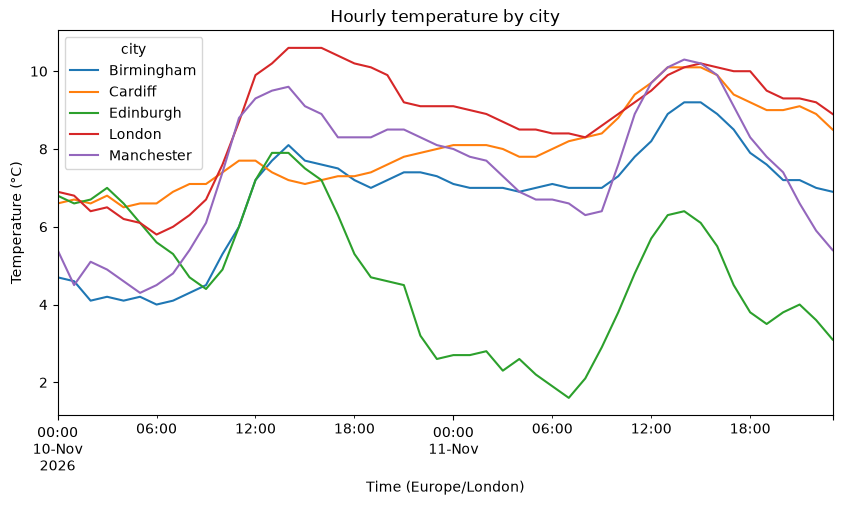

In [9]:
df["time"] = pd.to_datetime(df["time"])
pivot = df.drop_duplicates(["city", "time"]).pivot(index="time", columns="city", values="temperature_2m")
pivot.plot(figsize=(10, 5))
plt.title("Hourly temperature by city")
plt.xlabel("Time (Europe/London)")
plt.ylabel("Temperature (°C)")
plt.show()

m## Findings

1. `time` is loaded as text (`str`), not a datetime, so it must be converted before sorting or charting.
2. There are 480 duplicate rows on (city, time) out of 720, because the extract ran three times and each run returns the same overlapping 48 hours. The ETL must de-duplicate them.
3. Temperatures range from 1.6 °C to 10.6 °C with a mean of about 7.2 °C, which is realistic for the UK in November. Wind speeds are 0.7 to 19.4 km/h, so there are no extreme or impossible values.
4. There are no null values in any column, so no imputation is needed.
5. Weather code 3 (overcast) accounts for 435 of 720 rows (about 60%). Drizzle and rain codes (51, 53, 55, 61) are rare, and precipitation is 0 in at least 75% of hours.

## Findings

1. `time` is loaded as text (`str`), not a datetime, so it must be converted before sorting or charting.
2. There are 480 duplicate rows on (city, time) out of 720, because the extract ran three times and each run returns the same overlapping 48 hours. The ETL must de-duplicate them.
3. Temperatures range from 1.6 °C to 10.6 °C with a mean of about 7.2 °C, which is realistic for the UK in November. Wind speeds are 0.7 to 19.4 km/h, so there are no extreme or impossible values.
4. There are no null values in any column, so no imputation is needed.
5. Weather code 3 (overcast) accounts for 435 of 720 rows (about 60%). Drizzle and rain codes (51, 53, 55, 61) are rare, and precipitation is 0 in at least 75% of hours.